Resistance R: 467.3 ± 0.3 Ω
reduced chi squared: 0.10597753946096956


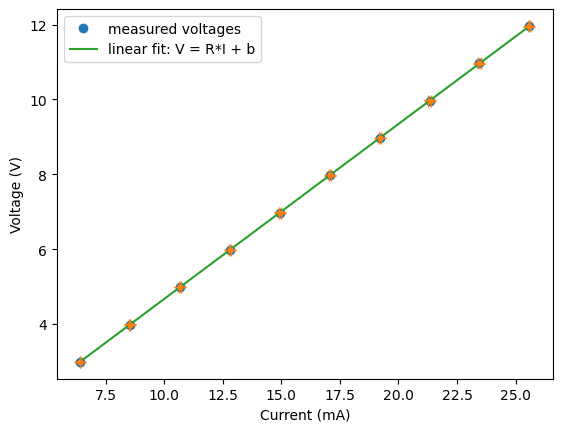

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#data
voltage, unc_v, current, unc_i = np.loadtxt("PHY244 ohm's law data - Sheet1.csv", skiprows = 1, delimiter = ',', comments = '#', unpack = True)
#unc: uncertainty

#linear model
def resistance_model(x,a,b):
    return a*x + b

#fit model to data
popt, pcov = curve_fit(resistance_model,
                    current,
                    voltage,
                    sigma = unc_v,
                    absolute_sigma = True,
                    p0=[2.0, 0.0])

pstd = (np.sqrt(np.diag(pcov)))

#plot data
plt.plot(current, voltage, "o", label="measured voltages")
plt.errorbar(current, voltage, xerr=unc_i, yerr=unc_v, ls='', marker='s', markersize=3, capsize=4, capthick=1)

#plot curve fit
plt.plot(current, resistance_model(current, *popt), label="linear fit: V = R*I + b")

#decorate the plot
plt.xlabel("Current (mA)")
plt.ylabel("Voltage (V)")
plt.legend()

#extract resistance (slope a) and its uncertainty directly
R = popt[0]*1000
u_R = pstd[0]*1000

#calculating resistance
print(f"Resistance R: {R:.1f} ± {u_R:.1f} Ω")

#chi squared
def chi_squared(data, model_values, uncertainty):
    difference = data - model_values
    diff_unc = difference / uncertainty
    diff_squared = diff_unc**2
    return np.sum(diff_squared)

def reduced_chi_squared(data, model_values, uncertainty, num_params=2):
    dof = len(data) - num_params
    return chi_squared(data, model_values, uncertainty) / dof

resistance_model_data = resistance_model(current, *popt)
red_chi2 = reduced_chi_squared(voltage, resistance_model_data, unc_v, num_params=2)
print("reduced chi squared:", red_chi2)